**The following plots and visualizations serve as documentation for tracking the evolution of the Koopman Deep Neural Network. The DNN is trained to learn Koopman embeddings in an inifinite-dimensional linear function space. The learned model is tested against ground-truth RK4 ODE state measurements.**

**The DNN is trained to learn one-step and multistep dynamics. However, it can be seen that while the model performs well at one-step prediction, multistep predictions diverge significantly as during training, the neural network uses it's own multistep rollout predictions as ground-truth. The errors compound quickly, causing rollout errors to increase. Most likely, this is because my RK4 solver solved for drone dynamics one time step into the future.**

**The next step is to implement a multistep rollout mechanism into the existing RK4 ODE solver, then retrain the DNN.**

**Revised 11/01/2026**

In [37]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path

CHECKPOINT = "best_model.pth"   # path to .pth file
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DT = 0.01

STATE_LABELS = [
    r"$p_x$", r"$p_y$", r"$p_z$",
    r"$v_x$", r"$v_y$", r"$v_z$",
    r"$\sin\phi$", r"$\cos\phi$",
    r"$\sin\theta$", r"$\cos\theta$",
    r"$\sin\psi$", r"$\cos\psi$",
    r"$p$", r"$q$", r"$r$"
]
print(f"Device: {DEVICE}")

Device: cpu


In [38]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [39]:
import os

def search_koopman_files(search_path):
    found = False
    for root, dirs, files in os.walk(search_path):
        for file in files:
            if 'koopman' in file.lower() and file.endswith('.py'):
                found = True
                print(f"Found: {os.path.join(root, file)}")
                print(f"Suggested sys.path: {os.path.abspath(os.path.join(root, '..'))}\n")
    if not found:
        print("No files containing 'koopman' and ending in '.py' were found in Google Drive.")
        print("Here are the top-level directories in your Drive to help verify your folder names:")
        try:
            print(os.listdir('/content/drive/MyDrive'))
        except Exception as e:
            print(f"Error listing Drive: {e}")

search_koopman_files('/content/drive/MyDrive')

Found: /content/drive/MyDrive/Drone Project/models/koopman_arch.py
Suggested sys.path: /content/drive/MyDrive/Drone Project



In [40]:
import sys
sys.path.append("/content/drive/MyDrive/Drone Project")
from models.koopman_arch import KoopmanModel

ckpt   = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=False)
config = ckpt["config"]
mu_x   = ckpt["mu_x"].cpu().numpy()   # (1, 15)
std_x  = ckpt["std_x"].cpu().numpy()  # (1, 15)
mu_u   = ckpt["mu_u"].cpu().numpy()
std_u  = ckpt["std_u"].cpu().numpy()

x_dim = mu_x.shape[1] # 15
z_dim = config["latent_dim"]
u_dim = mu_u.shape[1] # 4
dt = config.get("dt", DT)

model = KoopmanModel(x_dim=x_dim, z_dim=z_dim, u_dim=u_dim, dt=dt).to(DEVICE)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

latent_dim = config["latent_dim"]
print(f"Latent dim: {latent_dim}")
print(f"T_roll: {config.get('T_roll', 'N/A')}")
print(f"Config: {config}")

Latent dim: 20
T_roll: 38
Config: {'latent_dim': 20, 'dt': 0.01, 'gamma': 0.9077163258288745, 'lr_stage1': 0.0016357729380070546, 'lr_stage2': 0.00016688136630840244, 'N_stage1': 400, 'N_stage2': 600, 'patience_stage1': 10, 'patience': 50, 'w_recon': 0.4281280818294986, 'w_pred': 1.0525609581540984, 'w_lin': 0.5699668500515863, 'w_ms': 0.3967030154892973, 'w_pos': 0.34243776990561664, 'w_vel': 1.9512848518095507, 'w_att': 3.3026193909738066, 'w_dyn': 2.39267651657724, 'std_x': array([[17.90338   , 20.050312  ,  3.2861838 ,  4.295329  ,  5.326247  ,
         1.3226391 ,  0.20923606,  0.04242182,  0.19279556,  0.04185542,
         0.63900757,  0.7085838 ,  0.28312597,  0.26656348,  0.10047397]],
      dtype=float32), 'mu_x': array([[ 2.707035  ,  2.5716572 ,  7.566378  ,  1.0564796 ,  0.53409034,
        -0.7775455 ,  0.0756627 ,  0.97401726, -0.04929345,  0.979118  ,
         0.12713644,  0.27095124,  0.01009034, -0.01030718,  0.00835408]],
      dtype=float32), 'std_u': array([[0.77351

In [41]:
with torch.no_grad():
    if hasattr(model, 'K'):
        K = model.K.detach().cpu().numpy()
    elif hasattr(model, 'get_K'):
        K = model.get_K().detach().cpu().numpy()
    else:
        z_eye = torch.eye(latent_dim, device=DEVICE)
        u_zero = torch.zeros(latent_dim, config.get('control_dim', 4), device=DEVICE)
        z_next = model.step(z_eye, u_zero, DT)
        K = z_next.detach().cpu().numpy()

eigenvalues, eigenvectors = np.linalg.eig(K)
idx = np.argsort(-np.abs(eigenvalues))
eigenvalues  = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

print(f"K shape : {K.shape}")
print(f"\nTop-10 eigenvalues (|λ|, Re, Im, frequency Hz):")
print(f"{'#':>3}  {'|λ|':>6}  {'Re':>8}  {'Im':>8}  {'freq Hz':>9}")
print("-" * 44)
for i, ev in enumerate(eigenvalues[:10]):
    freq = np.angle(ev)/(2 * np.pi * DT)
    print(f"{i:>3}  {np.abs(ev):>6.4f}  {ev.real:>8.4f}  {ev.imag:>8.4f}  {freq:>9.3f}")

K shape : (20, 20)

Top-10 eigenvalues (|λ|, Re, Im, frequency Hz):
  #     |λ|        Re        Im    freq Hz
--------------------------------------------
  0  1.0442    1.0442    0.0000      0.000
  1  0.9978    0.9963   -0.0556     -0.888
  2  0.9978    0.9963    0.0556      0.888
  3  0.9978    0.9977   -0.0165     -0.263
  4  0.9978    0.9977    0.0165      0.263
  5  0.9977    0.9977    0.0085      0.136
  6  0.9977    0.9977   -0.0085     -0.136
  7  0.9972    0.9972    0.0083      0.132
  8  0.9972    0.9972   -0.0083     -0.132
  9  0.9969    0.9945    0.0692      1.106


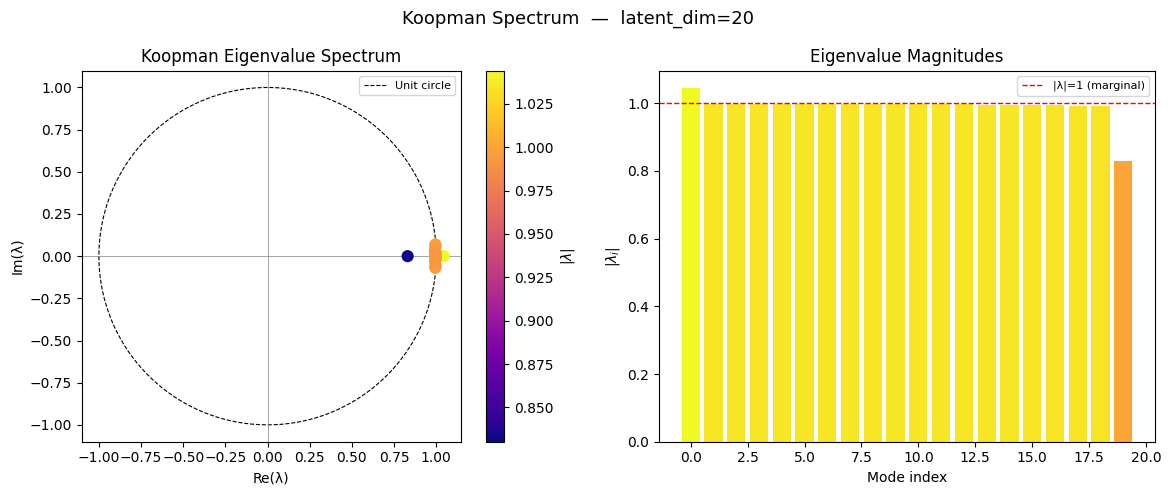

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ax = axes[0]
theta = np.linspace(0, 2*np.pi, 300)
ax.plot(np.cos(theta), np.sin(theta), 'k--', lw=0.8, label='Unit circle')
sc = ax.scatter(eigenvalues.real, eigenvalues.imag,
                c=np.abs(eigenvalues), cmap='plasma', s=60, zorder=3)
plt.colorbar(sc, ax=ax, label=r'$|\lambda|$')
ax.axhline(0, color='gray', lw=0.5)
ax.axvline(0, color='gray', lw=0.5)
ax.set_xlabel('Re(λ)'); ax.set_ylabel('Im(λ)')
ax.set_title('Koopman Eigenvalue Spectrum')
ax.set_aspect('equal')
ax.legend(fontsize=8)

ax = axes[1]
ax.bar(range(len(eigenvalues)), np.abs(eigenvalues),
       color=plt.cm.plasma(np.abs(eigenvalues) / (np.abs(eigenvalues).max() + 1e-8)))
ax.axhline(1.0, color='red', lw=1, ls='--', label='|λ|=1 (marginal)')
ax.set_xlabel('Mode index'); ax.set_ylabel(r'$|\lambda_i|$')
ax.set_title('Eigenvalue Magnitudes')
ax.legend(fontsize=8)

plt.suptitle(f'Koopman Spectrum  —  latent_dim={latent_dim}', fontsize=13)
plt.tight_layout()
plt.savefig('fig_spectrum.png', dpi=150)
plt.show()

Using 6 trajectory files
Embedding matrix: (5994, 20)


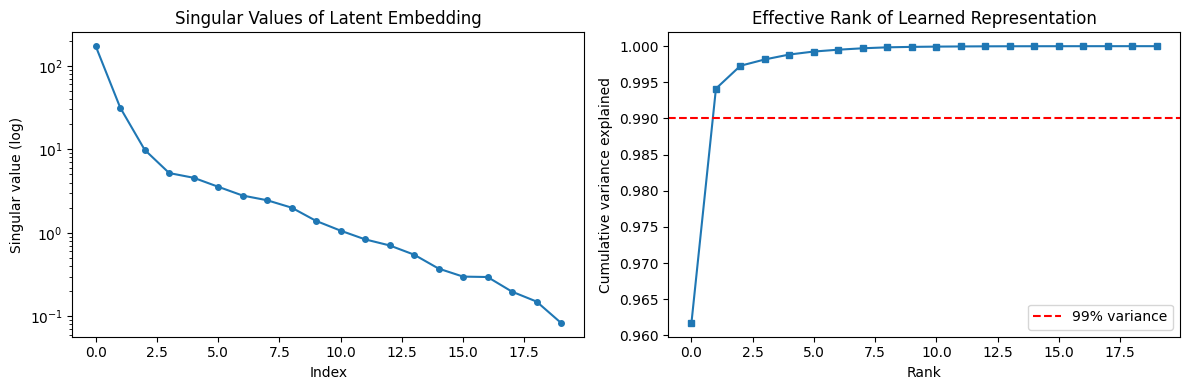

Rank to explain 99% variance: 2  (latent_dim=20)


In [43]:
import glob
import pandas as pd

DATA_GLOB = "/content/drive/MyDrive/Drone Project/**/*sin*.csv"
all_files = sorted(glob.glob(DATA_GLOB, recursive=True))

files = [f for f in all_files if "control_inputs" not in f][:6]
print(f"Using {len(files)} trajectory files")

if len(files) == 0:
    raise FileNotFoundError(f"No trajectory files matching pattern '{DATA_GLOB}' were found. Please verify your trajectory data location.")

Z_list = []
with torch.no_grad():
    for f in files:
        df = pd.read_csv(f)
        for col in ['traj_id', 'step', 'time']:
            if col in df.columns:
                df = df.drop(columns=[col])

        X = df.values.astype(np.float32)
        if X.shape[1] == 12:
            att = X[:, 6:9]
            X15 = np.hstack([
                X[:, :6],
                np.sin(att), np.cos(att),
                X[:, 9:12]
            ])
        else:
            X15 = X
        Xn = (X15 - mu_x)/std_x
        Xt = torch.from_numpy(Xn).float().to(DEVICE)
        Z  = model.encoder(Xt).cpu().numpy()
        Z_list.append(Z)

Z_all = np.vstack(Z_list)
print(f"Embedding matrix: {Z_all.shape}")

_, sv, _ = np.linalg.svd(Z_all, full_matrices=False)
explained = np.cumsum(sv**2) / np.sum(sv**2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].semilogy(sv, 'o-', ms=4)
axes[0].set_xlabel('Index'); axes[0].set_ylabel('Singular value (log)')
axes[0].set_title('Singular Values of Latent Embedding')
axes[1].plot(explained, 's-', ms=4)
axes[1].axhline(0.99, color='red', ls='--', label='99% variance')
axes[1].set_xlabel('Rank'); axes[1].set_ylabel('Cumulative variance explained')
axes[1].set_title('Effective Rank of Learned Representation')
axes[1].legend()
plt.tight_layout()
plt.savefig('fig_svd.png', dpi=150)
plt.show()

rank99 = int(np.searchsorted(explained, 0.99)) + 1
print(f"Rank to explain 99% variance: {rank99}  (latent_dim={latent_dim})")

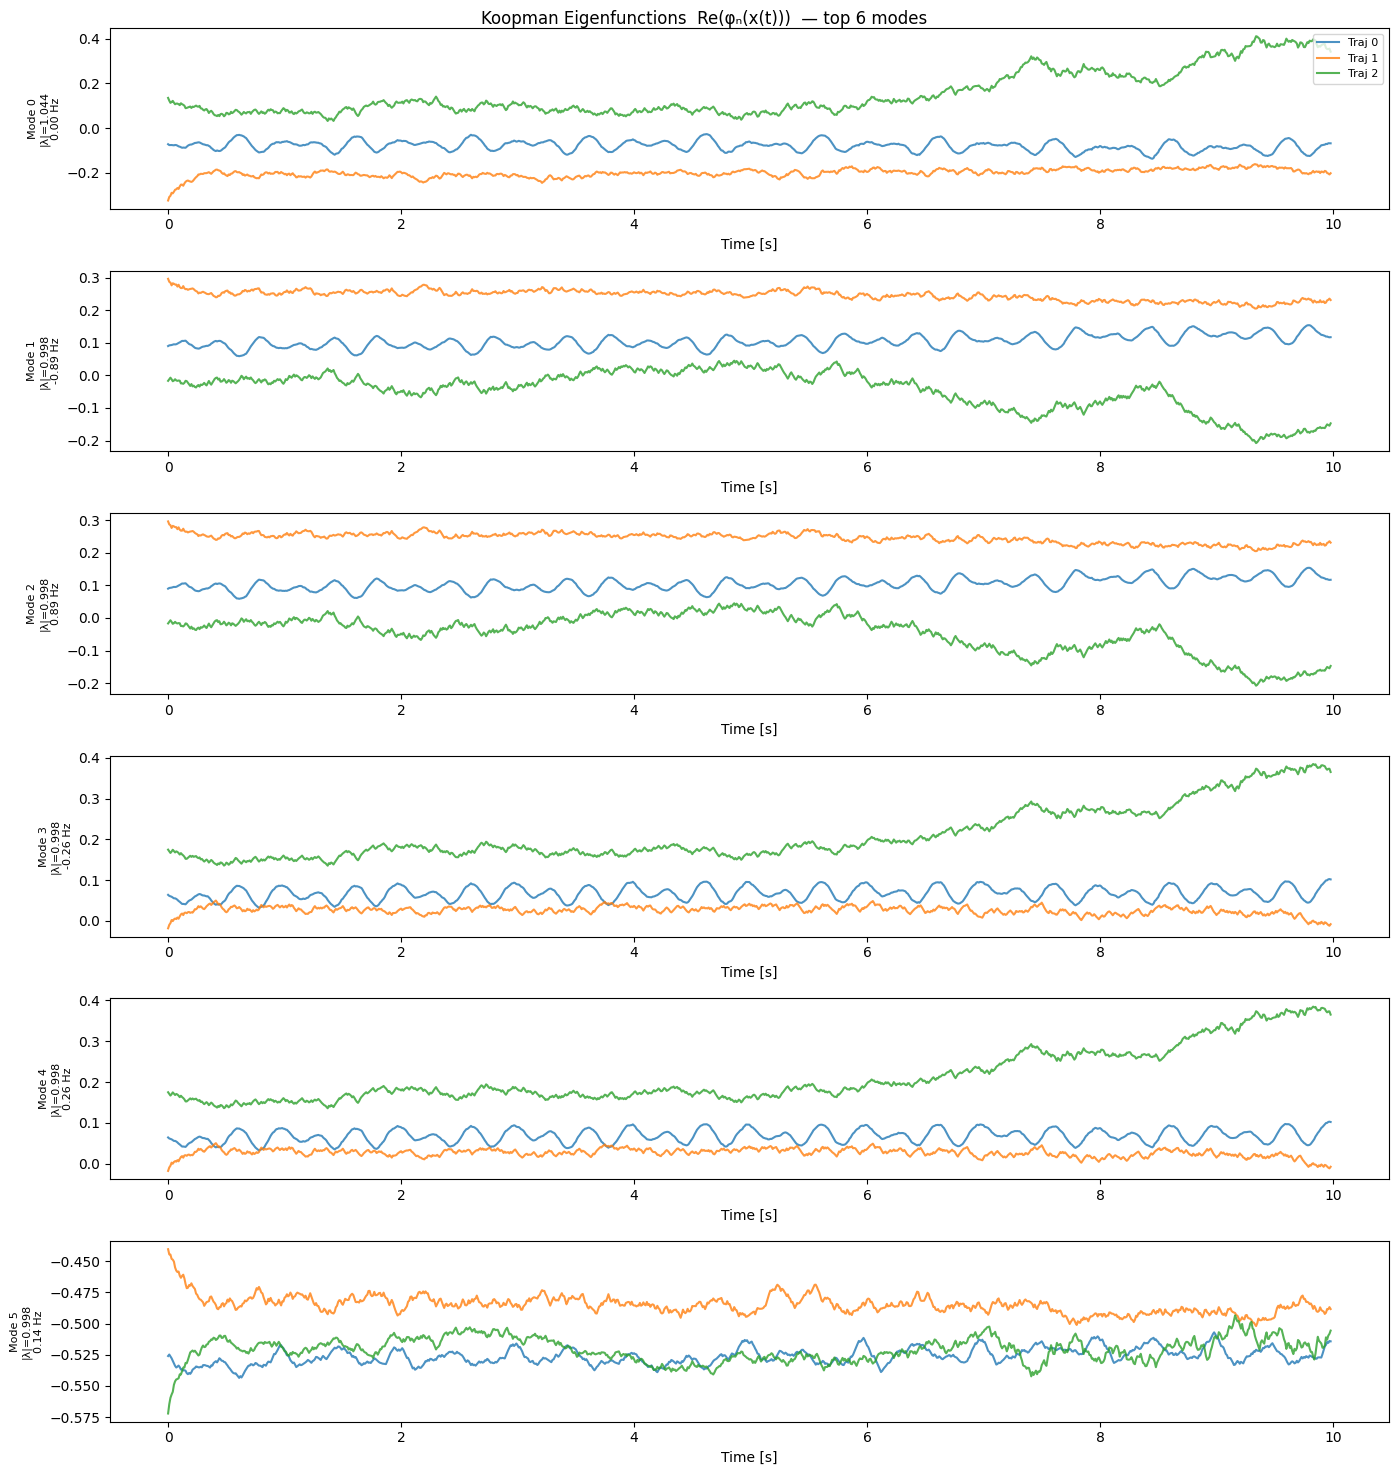

In [44]:
N_modes = min(6, latent_dim)
V = eigenvectors

fig, axes = plt.subplots(N_modes, 1, figsize=(14, 2.5*N_modes), sharex=False)

for traj_idx, Z in enumerate(Z_list[:3]):
    phi_modes = Z @ V[:, :N_modes]
    T = len(Z)
    t = np.arange(T) * DT
    for m in range(N_modes):
        ax = axes[m]
        lv = eigenvalues[m]
        freq = np.angle(lv) / (2*np.pi*DT)
        ax.plot(t, phi_modes[:, m].real,
                label=f'Traj {traj_idx}' if m == 0 else None,
                alpha=0.8)
        ax.set_ylabel(f'Mode {m}\n|λ|={np.abs(lv):.3f}\n{freq:.2f} Hz', fontsize=8)
        ax.set_xlabel('Time [s]')

axes[0].legend(fontsize=8, loc='upper right')
plt.suptitle('Koopman Eigenfunctions  Re(φₙ(x(t)))  — top 6 modes', fontsize=12)
plt.tight_layout()
plt.savefig('fig_eigenfunctions.png', dpi=150)
plt.show()

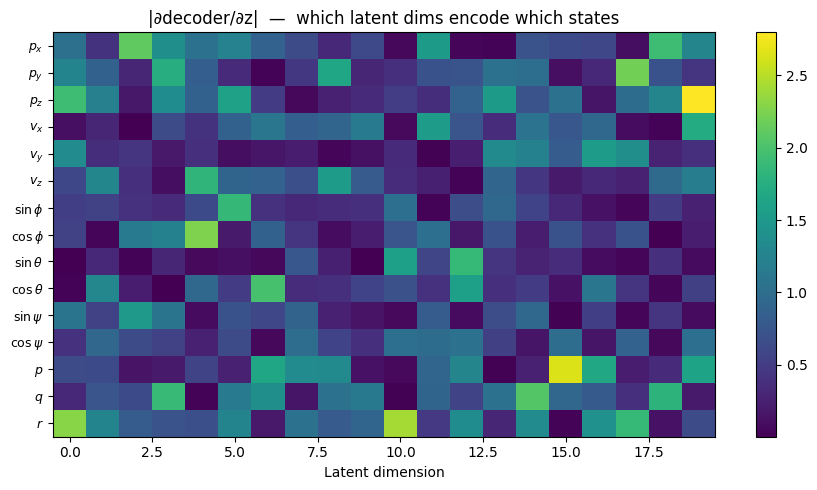

In [45]:
eps = 1e-4
J = np.zeros((15, latent_dim))
with torch.no_grad():
    z0 = torch.zeros(1, latent_dim, device=DEVICE)
    x0_dec = model.decoder(z0).cpu().numpy().squeeze()   # (15,)
    for j in range(latent_dim):
        dz = torch.zeros(1, latent_dim, device=DEVICE)
        dz[0, j] = eps
        xp = model.decoder(z0 + dz).cpu().numpy().squeeze()
        J[:, j] = (xp - x0_dec) / eps

fig, ax = plt.subplots(figsize=(max(8, latent_dim*0.45), 5))
im = ax.imshow(np.abs(J), aspect='auto', cmap='viridis')
ax.set_yticks(range(15))
ax.set_yticklabels(STATE_LABELS, fontsize=9)
ax.set_xlabel('Latent dimension')
ax.set_title('|∂decoder/∂z|  —  which latent dims encode which states')
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig('fig_decoder_map.png', dpi=150)
plt.show()

In [46]:
import os
import pandas as pd
import numpy as np
import torch

STATE_FILE = files[0]
GLOBAL_CTRL_FILE = "/content/drive/MyDrive/control_inputs_sin.csv"
if not os.path.exists(GLOBAL_CTRL_FILE):
    GLOBAL_CTRL_FILE = "/content/drive/MyDrive/Drone Project/control_inputs_sin.csv"

print(f"Loading State File:   {os.path.basename(STATE_FILE)}")
print(f"Loading Control File: {os.path.basename(GLOBAL_CTRL_FILE)}")

df_state = pd.read_csv(STATE_FILE, header=None)
X_gt_raw = df_state.values.astype(np.float32)

df_ctrl = pd.read_csv(GLOBAL_CTRL_FILE)
traj_id = 0
if 'traj_id' in df_ctrl.columns:
    df_ctrl_filtered = df_ctrl[df_ctrl['traj_id'] == traj_id].copy()
else:
    df_ctrl_filtered = df_ctrl.iloc[:len(X_gt_raw)]

for col in ['traj_id', 'step', 'time', 'ic_label', 't']:
    if col in df_ctrl_filtered.columns:
        df_ctrl_filtered = df_ctrl_filtered.drop(columns=[col])
U_raw = df_ctrl_filtered.values.astype(np.float32)

if X_gt_raw.shape[1] == 12:
    att = X_gt_raw[:, 6:9]
    X_gt = np.hstack([X_gt_raw[:, :6], np.sin(att), np.cos(att), X_gt_raw[:, 9:12]])
else:
    X_gt = X_gt_raw

T_PLOT = 200
X_gt = X_gt[:T_PLOT+1]
U = U_raw[:T_PLOT]

Xn = (X_gt - mu_x) / std_x
Un = (U - mu_u) / std_u

X_koop = np.zeros_like(Xn)
X_koop[0] = Xn[0]

with torch.no_grad():
    x_prev_t = torch.from_numpy(Xn[0:1]).float().to(DEVICE)
    z = model.encoder(x_prev_t)
    for k in range(T_PLOT):
        u_t = torch.from_numpy(Un[k:k+1]).float().to(DEVICE)
        z = model.step(z, u_t, DT)
        x_dec = model.decoder(z, x_prev=x_prev_t).cpu().numpy().squeeze()
        X_koop[k+1] = x_dec
        if np.any(np.isnan(x_dec)) or np.any(np.isinf(x_dec)):
            print(f"--> Rollout exploded at step {k}!")
            X_koop[k+1:] = X_koop[k]
            break
        x_prev_t = torch.from_numpy(x_dec[None]).float().to(DEVICE)

X_gt_phys = X_gt * std_x + mu_x
X_koop_phys = X_koop * std_x + mu_x

mask = ~np.isnan(X_koop_phys).any(axis=1)
RMSE = np.sqrt(np.mean((X_gt_phys[mask] - X_koop_phys[mask])**2, axis=0))

print("\nPer-state RMSE (physical units):")
for i, (label, rmse) in enumerate(zip(STATE_LABELS, RMSE)):
    print(f" {label:>14s}: {rmse:.4f}")

Loading State File:   state_history_x0_0sin.csv
Loading Control File: control_inputs_sin.csv
--> Rollout exploded at step 147!

Per-state RMSE (physical units):
          $p_x$: 7.3700
          $p_y$: 8.9920
          $p_z$: 25.0396
          $v_x$: 5.2040
          $v_y$: 5.7763
          $v_z$: 2.4577
     $\sin\phi$: 0.2677
     $\cos\phi$: 0.1179
   $\sin\theta$: 0.2371
   $\cos\theta$: 0.1482
     $\sin\psi$: 0.5325
     $\cos\psi$: 0.8034
            $p$: 0.6947
            $q$: 0.6943
            $r$: 0.2363


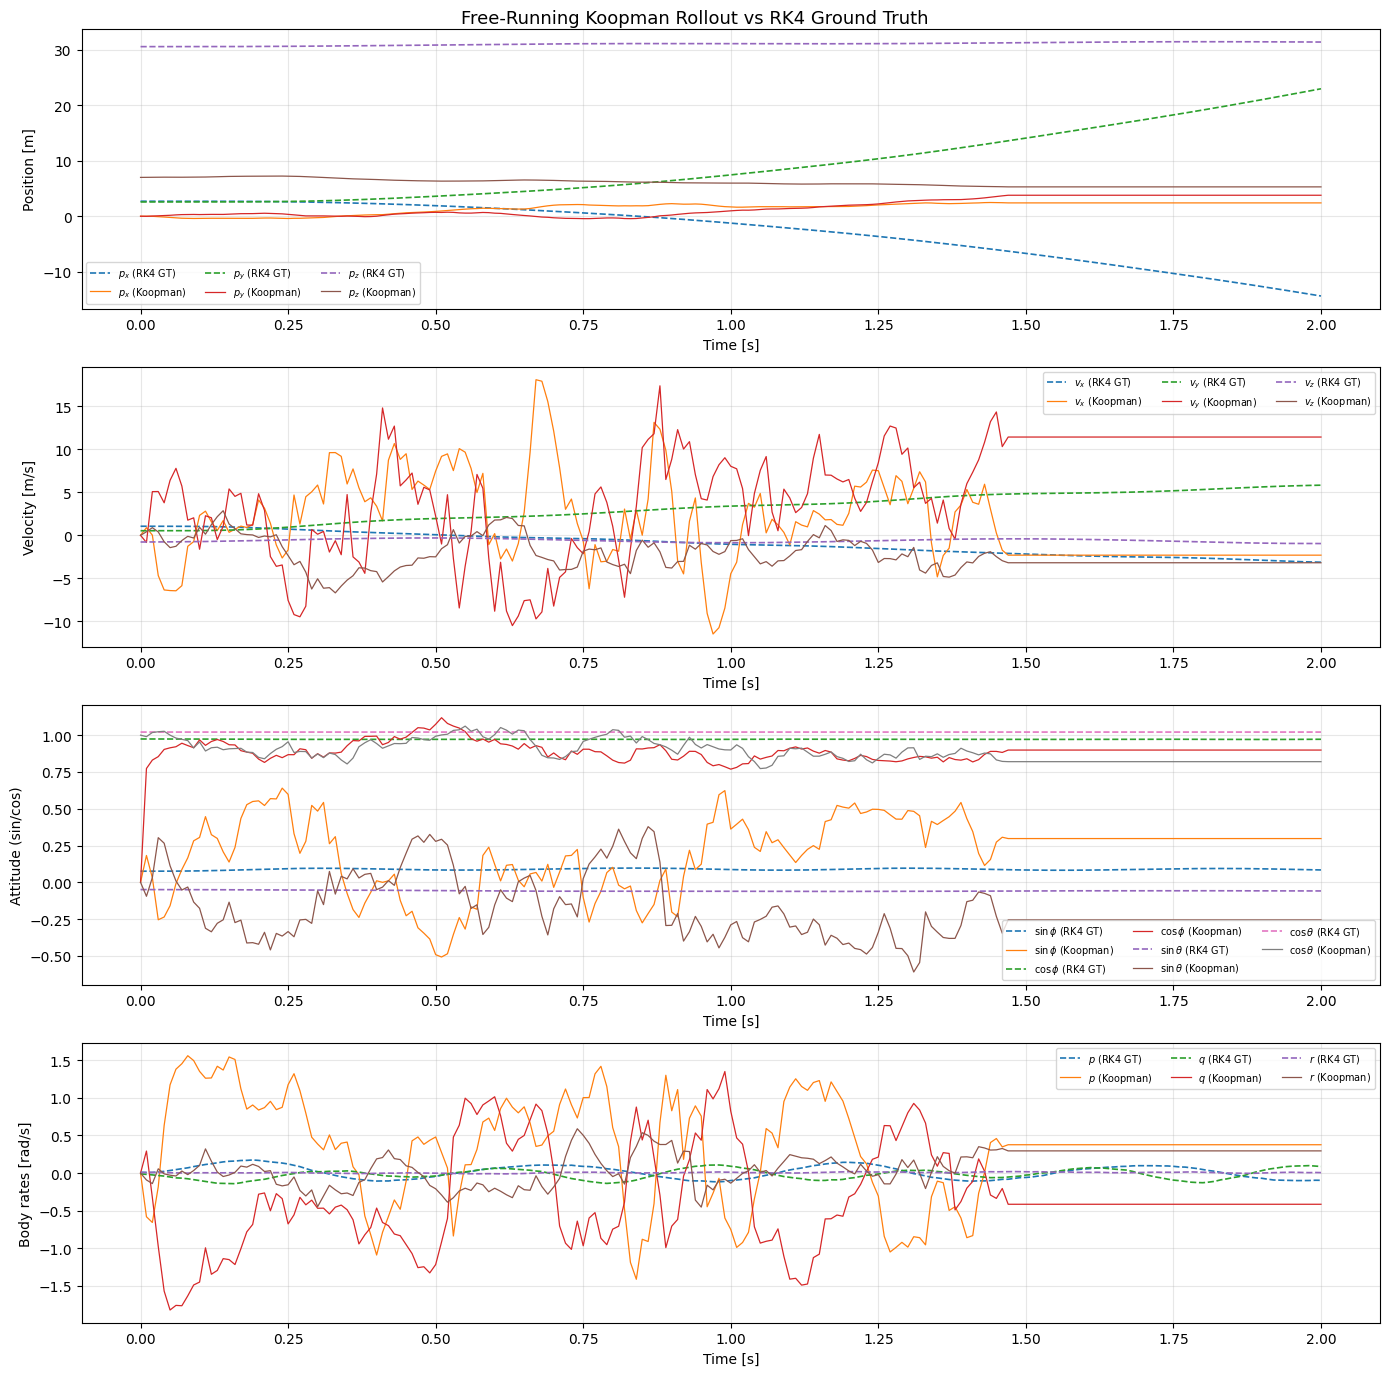

In [47]:
STATE_GROUPS = {
    'Position [m]':    ([0, 1, 2], [r'$p_x$', r'$p_y$', r'$p_z$']),
    'Velocity [m/s]':  ([3, 4, 5], [r'$v_x$', r'$v_y$', r'$v_z$']),
    'Attitude (sin/cos)': ([6, 7, 8, 9], [r'$\sin\phi$', r'$\cos\phi$', r'$\sin\theta$', r'$\cos\theta$']),
    'Body rates [rad/s]': ([12, 13, 14], [r'$p$', r'$q$', r'$r$']),
}

fig, axes = plt.subplots(4, 1, figsize=(14, 14))
for ax, (title, (idxs, labels)) in zip(axes, STATE_GROUPS.items()):
    for i, lbl in zip(idxs, labels):
        ax.plot(t_ax, X_gt_phys[:, i],   '--', lw=1.2, label=f'{lbl} (RK4 GT)')
        ax.plot(t_ax, X_koop_phys[:, i], '-',  lw=0.9, label=f'{lbl} (Koopman)')
    ax.set_ylabel(title)
    ax.set_xlabel('Time [s]')
    ax.legend(fontsize=7, ncol=3)
    ax.grid(True, alpha=0.3)

plt.suptitle('Free-Running Koopman Rollout vs RK4 Ground Truth', fontsize=13)
plt.tight_layout()
plt.savefig('fig_rollout.png', dpi=150)
plt.show()

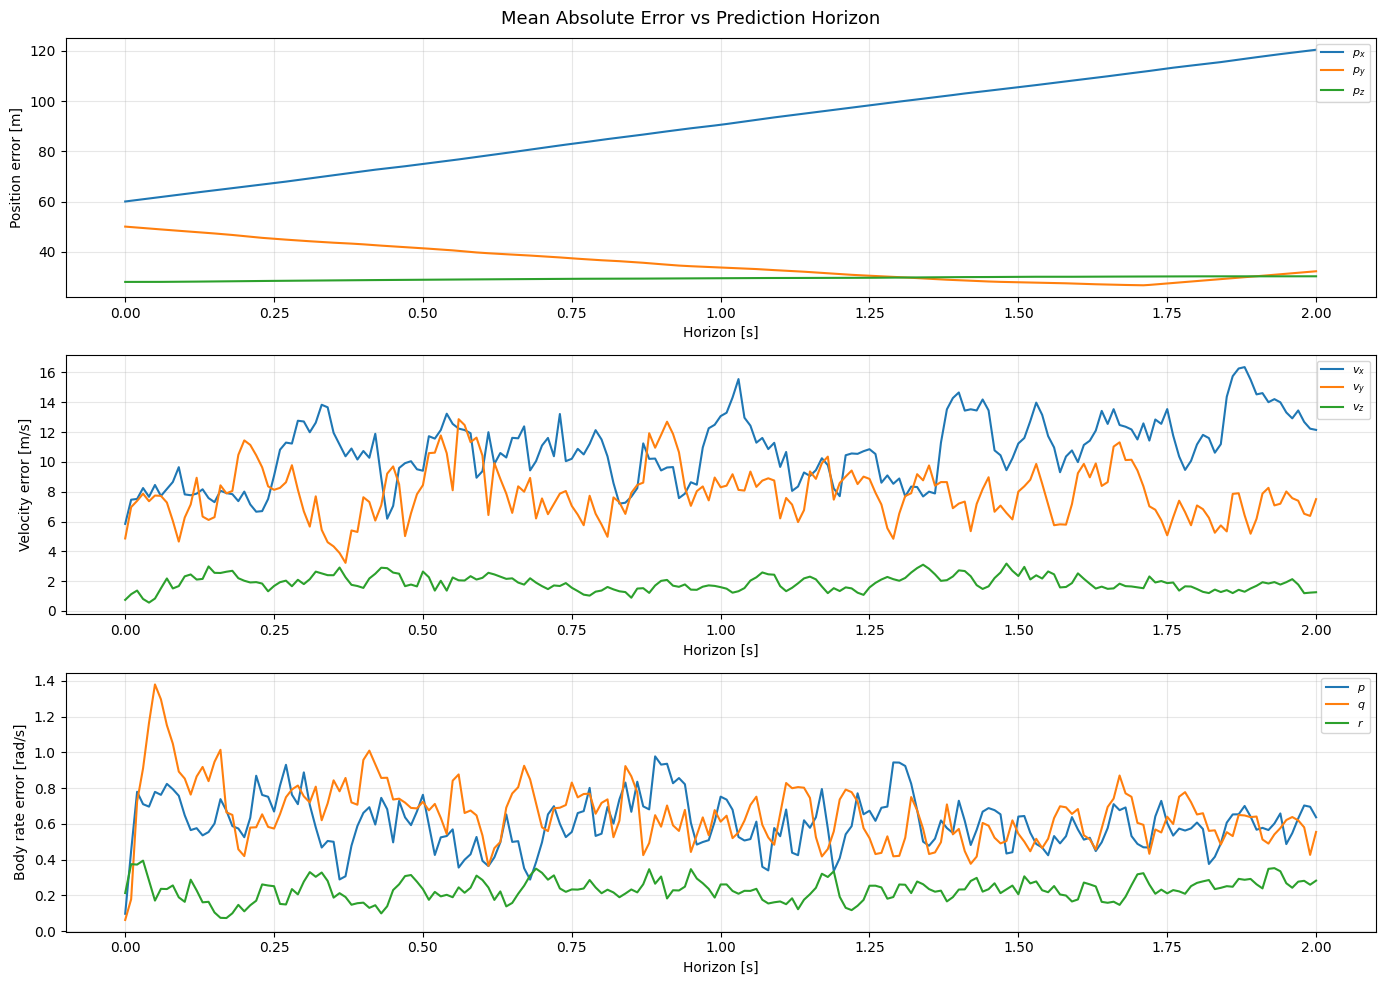

In [48]:
horizon_rmse = {label: [] for label in STATE_LABELS}
GLOBAL_CTRL_FILE = "/content/drive/MyDrive/control_inputs_sin.csv"
if not os.path.exists(GLOBAL_CTRL_FILE):
    GLOBAL_CTRL_FILE = "/content/drive/MyDrive/Drone Project/control_inputs_sin.csv"

df_ctrl_all = pd.read_csv(GLOBAL_CTRL_FILE)

for file_idx, (f, Z) in enumerate(zip(files, Z_list)):
    df_state = pd.read_csv(f, header=None)
    X_raw = df_state.values.astype(np.float32)

    if X_raw.shape[1] == 12:
        att = X_raw[:, 6:9]
        X15 = np.hstack([X_raw[:,:6], np.sin(att), np.cos(att), X_raw[:,9:]])
    else:
        X15 = X_raw
    if 'traj_id' in df_ctrl_all.columns:
        df_ctrl_filtered = df_ctrl_all[df_ctrl_all['traj_id'] == file_idx].copy()
    else:
        df_ctrl_filtered = df_ctrl_all.iloc[:len(X15)]
    for col in ['traj_id', 'step', 'time', 'ic_label', 't']:
        if col in df_ctrl_filtered.columns:
            df_ctrl_filtered = df_ctrl_filtered.drop(columns=[col])
    U_f = df_ctrl_filtered.values.astype(np.float32)

    T_avail = min(len(X15)-1, len(U_f), T_PLOT)

    Xn_f = (X15[:T_avail+1] - mu_x) / std_x
    Un_f = (U_f[:T_avail]   - mu_u) / std_u

    X_koop_f = np.zeros_like(Xn_f)
    X_koop_f[0] = Xn_f[0]
    with torch.no_grad():
        x_prev_t = torch.from_numpy(Xn_f[0:1]).float().to(DEVICE)
        z_f = model.encoder(x_prev_t)
        for k in range(T_avail):
            u_t = torch.from_numpy(Un_f[k:k+1]).float().to(DEVICE)
            z_f = model.step(z_f, u_t, DT)
            xd  = model.decoder(z_f, x_prev=x_prev_t).cpu().numpy().squeeze()
            if np.any(np.isnan(xd)) or np.any(np.isinf(xd)):
                X_koop_f[k+1:] = X_koop_f[k]
                break
            X_koop_f[k+1] = xd
            x_prev_t = torch.from_numpy(xd[None]).float().to(DEVICE)

    X_gt_p   = X15[:T_avail+1] * std_x + mu_x
    X_koop_p = X_koop_f        * std_x + mu_x

    err = np.abs(X_gt_p - X_koop_p)   # (T+1, 15)
    for i, label in enumerate(STATE_LABELS):
        if len(horizon_rmse[label]) == 0:
            horizon_rmse[label] = err[:, i]
        else:
            min_len = min(len(horizon_rmse[label]), len(err[:, i]))
            horizon_rmse[label] = horizon_rmse[label][:min_len] + err[:min_len, i]

n_traj = len(files)
fig, axes = plt.subplots(3, 1, figsize=(14, 10))
state_sets = [
    ([0,1,2],   'Position error [m]'),
    ([3,4,5],   'Velocity error [m/s]'),
    ([12,13,14],'Body rate error [rad/s]'),
]
for ax, (idxs, ylabel) in zip(axes, state_sets):
    for i in idxs:
        lbl = STATE_LABELS[i]
        err_i = horizon_rmse[lbl] / n_traj
        t_i   = np.arange(len(err_i)) * DT
        ax.plot(t_i, err_i, label=lbl)
    ax.set_ylabel(ylabel)
    ax.set_xlabel('Horizon [s]')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle('Mean Absolute Error vs Prediction Horizon', fontsize=13)
plt.tight_layout()
plt.savefig('fig_error_growth.png', dpi=150)
plt.show()